# Medidas de Dispersão — Variância, Desvio Padrão e Coeficiente de Variação

---

## 1. Contextualização e Importação de Bibliotecas

Nesta aula, vamos avançar na análise exploratória compreendendo o quanto os dados se afastam da média aritmética. Duas operações comerciais podem ter exatamente a mesma média de vendas, mas comportamentos de risco completamente distintos.

Execute a célula abaixo para importar as bibliotecas necessárias.

In [2]:
import numpy as np
import pandas as pd

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


## 2. Prática Orientada — Parte 1: Cálculo Passo a Passo em Python Puro

Para entender a lógica matemática por trás da **Variância** e do **Desvio Padrão**, vamos implementar os 5 passos manuais utilizando apenas Python nativo sobre o conjunto `[2, 4, 6, 8, 10]`:
1. Calcular a média aritmética ($\mu$).
2. Calcular os desvios individuais ($x_i - \mu$).
3. Elevar cada desvio ao quadrado ($(x_i - \mu)^2$) para eliminar sinais negativos e penalizar grandes afastamentos.
4. Calcular a média dos quadrados dos desvios (**Variância**).
5. Extrair a raiz quadrada da variância (**Desvio Padrão**) para retornar à unidade original dos dados.

In [2]:
dados = [2, 4, 6, 8, 10]

# Passo 1: Calcular a média
media = sum(dados) / len(dados)
print(f"1. Média: {media}")

# Passo 2: Calcular as diferenças (desvios) entre cada valor e a média
diferencas = [x - media for x in dados]
print(f"2. Diferenças em relação à média: {diferencas}")

# Passo 3: Elevar as diferenças ao quadrado
quadrados_diferencas = [x ** 2 for x in diferencas]
print(f"3. Quadrados das diferenças: {quadrados_diferencas}")

# Passo 4: Calcular a média dos quadrados das diferenças (Variância Populacional)
variancia_manual = sum(quadrados_diferencas) / len(quadrados_diferencas)
print(f"4. Variância (média dos quadrados das diferenças): {variancia_manual}")

# Passo 5: Calcular a raiz quadrada da variância (Desvio Padrão)
desvio_padrao_manual = variancia_manual ** 0.5
print(f"5. Desvio Padrão: {desvio_padrao_manual:.4f}")

1. Média: 6.0
2. Diferenças em relação à média: [-4.0, -2.0, 0.0, 2.0, 4.0]
3. Quadrados das diferenças: [16.0, 4.0, 0.0, 4.0, 16.0]
4. Variância (média dos quadrados das diferenças): 8.0
5. Desvio Padrão: 2.8284


## 3. Prática Orientada — Parte 2: NumPy, Pandas e Critérios de Diagnóstico

Na prática profissional, utilizamos as funções otimizadas do **NumPy** e do **Pandas**.

> **Atenção Técnica (`ddof` - Delta Degrees of Freedom):**
> * O **NumPy** (`np.var`, `np.std`) usa por padrão `ddof=0` (variância populacional, dividindo por $N$).
> * O **Pandas** (`Series.var()`, `Series.std()`) usa por padrão `ddof=1` (variância amostral, dividindo por $N - 1$).
> * Para alinhar ao cálculo populacional manual, informamos `ddof=0`.

### Regras de Avaliação da Dispersão (Referência da UC)
* **Distância da Variância:** $\text{Distância} = \frac{\text{Variância}}{\text{Média}^2}$
  * $\le 10\%$: Baixa dispersão dos dados em relação à média
  * $> 10\%$ e $< 25\%$: Dispersão moderada dos dados em relação à média
  * $\ge 25\%$: Alta dispersão dos dados em relação à média
* **Coeficiente de Variação (CV):** $CV = \frac{\text{Desvio Padrão}}{\text{Média}}$

In [3]:
dados_serie = pd.Series([2, 4, 6, 8, 10])

var_np = np.var(dados_serie, ddof=0)
dp_np = np.std(dados_serie, ddof=0)

# Métricas de avaliação
distancia_var = var_np / (dados_serie.mean() ** 2)
coef_variacao = dp_np / dados_serie.mean()

print(f"Variância NumPy (ddof=0): {var_np:.4f}")
print(f"Desvio Padrão NumPy (ddof=0): {dp_np:.4f}")
print(f"Variância Pandas Amostral (ddof=1): {dados_serie.var():.4f}")
print(f"Distância da Variância em relação à média²: {distancia_var:.2%}")
print(f"Coeficiente de Variação (CV): {coef_variacao:.2%}")

# Classificação automática
if distancia_var <= 0.10:
    status = "Baixa dispersão dos dados em relação à média"
elif distancia_var < 0.25:
    status = "Dispersão moderada dos dados em relação à média"
else:
    status = "Alta dispersão dos dados em relação à média"

print(f"\nDiagnóstico: {status}")

Variância NumPy (ddof=0): 8.0000
Desvio Padrão NumPy (ddof=0): 2.8284
Variância Pandas Amostral (ddof=1): 10.0000
Distância da Variância em relação à média²: 22.22%
Coeficiente de Variação (CV): 47.14%

Diagnóstico: Dispersão moderada dos dados em relação à média


---
## 4. Laboratório Prático — Estudo de Caso: *Data Organized*

### Cenário
Você atua como estagiário de dados na **Data Organized** (Curitiba-PR). O Analista Sênior liberou no *container* de homologação os registros de faturamento diário (em milhares de reais) dos últimos 10 dias úteis de três equipes comerciais:
* **Equipe Alpha (Varejo)**
* **Equipe Beta (Corporativo B2B)**
* **Equipe Gamma (E-commerce)**

A diretoria precisa decidir em qual equipe investir capital de giro imediato, priorizando aquela que apresenta **maior estabilidade e previsibilidade de caixa** (menor dispersão relativa).

### Entregáveis
1. Estruturar os dados em um `DataFrame` do Pandas.
2. Calcular para cada equipe: **Média, Mediana, Amplitude Total, IQR ($Q3 - Q1$), Variância (`ddof=0`), Desvio Padrão (`ddof=0`), Distância da Variância e Coeficiente de Variação (CV)**.
3. Classificar cada equipe quanto ao nível de dispersão.
4. Responder às questões de negócio ao final.

In [4]:
# Dados extraídos do container de vendas (em R$ mil)
equipe_alpha = [48, 50, 51, 49, 50, 52, 49, 50, 51, 50]
equipe_beta  = [20, 80, 15, 85, 30, 70, 25, 75, 10, 90]
equipe_gamma = [100, 105, 95, 110, 90, 102, 98, 104, 96, 100]

# 1. Crie o DataFrame df_vendas abaixo:
df_vendas = pd.DataFrame({
    'Equipe_Alpha': equipe_alpha,
    'Equipe_Beta': equipe_beta,
    'Equipe_Gamma': equipe_gamma
})

df_vendas

,Equipe_Alpha,Equipe_Beta,Equipe_Gamma
0,48,20,100
1,50,80,105
2,51,15,95
3,49,85,110
4,50,30,90
5,52,70,102
6,49,25,98
7,50,75,104
8,51,10,96
9,50,90,100


In [30]:
# 2 e 3. Desenvolva aqui o código para calcular todas as métricas e classificar cada equipe:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

equipe_alpha = np.array([48, 50, 51, 49, 50, 52, 49, 50, 51, 50])
equipe_beta  = np.array([20, 80, 15, 85, 30, 70, 25, 75, 10, 90])
equipe_gamma = np.array([100, 105, 95, 110, 90, 102, 98, 104, 96, 100])



def calcular_metricas(equipe):
    media = np.mean(equipe)
    amplitude = np.max(equipe) - np.min(equipe)
    variancia = np.var(equipe, ddof=0)
    desvio_padrao = np.std(equipe, ddof=0)
    dist_var = variancia / media**2
    cv = (desvio_padrao / media) * 100
    q1, q3 = np.percentile(equipe, [25, 75])
    iqr = q3-q1
    return {
        'Média Aritmética': round(media, 2),
        'Amplitude Total': round(amplitude, 2),
        'Variância (V)': round(variancia, 3),
        'Distância da Variância em %': round(dist_var*100,2),
        'Desvio Padrão (DP)': round(desvio_padrao, 2),
        'Coef. Variação (CV %)': round(cv, 2),
        'IQR':round(iqr,2)
    }


resultados = pd.DataFrame({
    'Equipe Alpha': calcular_metricas(equipe_alpha),
    'Equipe Beta': calcular_metricas(equipe_beta),
    'Equipe Gamma': calcular_metricas(equipe_gamma)
})

resultados

#print (f'Equipe Alpha tem a menor dispersão, sendo a melhor escolha, logo depois, a Equipe Gamma tem dispersão baixa, seguida pela Equipe Beta, que tem a dispersão alta.')

,Equipe Alpha,Equipe Beta,Equipe Gamma
Média Aritmética,50.00,50.00,100.00
Amplitude Total,4.00,80.00,20.00
Variância (V),1.20,950.00,29.00
Distância da Variância em %,0.05,38.00,0.29
Desvio Padrão (DP),1.10,30.82,5.39
Coef. Variação (CV %),2.19,61.64,5.39
IQR,1.50,57.50,7.00


### 4. Análise Crítica (Choque de Ideias — Responda abaixo)

1. **Por que comparar apenas o Desvio Padrão entre Alpha e Gamma pode induzir a um erro de interpretação, e como o Coeficiente de Variação resolve esse problema?**
   * *Sua resposta:* 

2. **Qual equipe deve receber o aporte de capital de giro e por quê?**
   * *Sua resposta:* 

---
## 5. Gabarito Comentado (Uso do Instrutor / Autocorreção)

Execute a célula abaixo apenas após concluir a sua resolução para conferir os resultados.

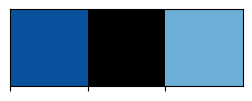

In [7]:
import seaborn as sns
sns.palplot(['#08519c', '#000000', '#6baed6'])

In [19]:
resumo = []
for col in df_vendas.columns:
    s = df_vendas[col]
    media = s.mean()
    mediana = s.median()
    amp = s.max() - s.min()
    iqr = np.percentile(s, 75) - np.percentile(s, 25)
    var = np.var(s, ddof=0)
    dp = np.std(s, ddof=0)
    dist_var = var / (media ** 2)
    cv = dp / media
    
    if dist_var <= 0.10:
        classif = "Baixa dispersão"
    elif dist_var < 0.25:
        classif = "Dispersão moderada"
    else:
        classif = "Alta dispersão"
        
    resumo.append({
        'Equipe': col,
        'Média': media,
        'Mediana': mediana,
        'Amplitude': amp,
        'IQR': iqr,
        'Variância': round(var, 2),
        'Desvio_Padrão': round(dp, 2),
        'Dist_Var_%': round(dist_var * 100, 2),
        'CV_%': round(cv * 100, 2),
        'Classificação': classif
    })

df_resultado = pd.DataFrame(resumo)
display(df_resultado)

,Equipe,Média,Mediana,Amplitude,IQR,Variância,Desvio_Padrão,Dist_Var_%,CV_%,Classificação
0,Equipe Alpha,9.998333,1.845,48.90,2.2725,320.98,17.92,321.09,179.19,Alta dispersão
1,Equipe Beta,204.993333,59.570,919.18,23.5350,111220.34,333.50,264.67,162.69,Alta dispersão
2,Equipe Gamma,27.796667,13.500,94.61,20.9575,1118.70,33.45,144.79,120.33,Alta dispersão
